# 04. Escenarios condicionados al estado del mercado

## 1. ¿Cómo incorporar el estado del mercado a nuestros escenarios?

En la notebook 03 construimos escenarios seleccionando observaciones históricas completas. Primero asignamos la misma probabilidad a todas las sesiones; después dimos mayor peso a las recientes.

Sin embargo, la antigüedad de una observación no describe las condiciones que precedieron a sus movimientos. Una sesión reciente puede haber ocurrido en un entorno distinto del que queremos representar.

Esto plantea una nueva pregunta: ¿podemos modificar las probabilidades históricas para dar relevancia a las condiciones del mercado, además de a la recencia?

Para investigarlo incorporamos el VIX como una primera variable de estado. Cada vector histórico de 125 retornos tiene asociado un nivel previo del índice, siguiendo una convención temporal explícita.

Los retornos observados no cambian. Lo que investigaremos es cómo asignarles probabilidades distintas según el estado que queremos representar. Que podamos construir esa distribución no demuestra todavía que produzca mejores pronósticos.

### ¿Qué observaciones podemos utilizar?

$A$ original contiene 2,204 observaciones conjuntas de 125 instrumentos. La tabla de auditoría conserva esas 2,204 filas: hay 2,203 filas alineadas y una no alineable por falta de antecedente dentro del calendario publicado. El subconjunto de trabajo conserva exactamente los retornos originales y el orden de instrumentos. Las comparaciones posteriores dentro de esta notebook utilizarán la misma muestra alineada para todos los métodos.

Para un instrumento $j$, el retorno logarítmico fechado en la sesión $x$ es:

$$\ell[x,j] = \log\left(\frac{P[x,j]}{P[x-1,j]}\right).$$

Aquí $x-1$ y $x-2$ son sesiones del calendario de acciones del corte publicado, no días calendario ni posiciones del calendario propio de VIX. El retorno fechado en $x$ va del cierre de $x-1$ al cierre de $x$; su VIX asociado corresponde a $x-2$. La regla deja una sesión completa de margen para publicación.

Alpha Vantage comunicó disponibilidad habitual para las 22:00 US/Eastern. Es una convención de disponibilidad, no una verificación histórica point-in-time ni garantía de ausencia de revisiones.

## 2. Carga y validación offline

Esta notebook es autónoma: no ejecuta las notebooks 02 o 03, no usa API ni credenciales y no persiste matrices nuevas. Recupera los log-retornos con el mismo procedimiento validado en la notebook 02 y verifica las referencias de integridad disponibles. Los hashes de los Parquet matriciales registrados durante la alineación fueron calculados en esa ejecución; el manifiesto sellado del corte no aporta hashes históricos de referencia para esos dos Parquet.

In [1]:
from __future__ import annotations

import hashlib
import json
import math
import site
import sys
from datetime import date
from pathlib import Path

import numpy as np

def find_project_root() -> Path:
    def is_project_root(candidate: Path) -> bool:
        return ((candidate / 'config' / 'universe.csv').is_file()
                and (candidate / 'src' / 'scenario_portfolio_lab').is_dir())

    for origin in (Path.cwd(), *Path.cwd().parents):
        for candidate in (origin, origin / 'scenario-portfolio-lab', origin / 'data-science-portfolio' / 'scenario-portfolio-lab'):
            if is_project_root(candidate):
                return candidate
    raise RuntimeError(
        'Repository files config/universe.csv and src/scenario_portfolio_lab were not found. '
        'Open this notebook from the complete scenario-portfolio-lab repository (or its data-science-portfolio parent). '
        'Do not run it from an exported standalone .ipynb file.'
    )


ROOT = find_project_root()
SRC = ROOT / 'src'
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

# MyST/Jupyter kernels may differ from the project virtual environment.
# Reuse already installed local dependencies when this Windows project .venv exists; never install packages here.
LOCAL_SITE_PACKAGES = ROOT / '.venv' / 'Lib' / 'site-packages'
if LOCAL_SITE_PACKAGES.is_dir():
    site.addsitedir(str(LOCAL_SITE_PACKAGES))

try:
    import exchange_calendars as xcals
    import polars as pl
except ModuleNotFoundError as exc:
    raise RuntimeError(
        'Missing project dependencies. Select the project .venv Python 3.13.2 kernel or install requirements.txt '
        'into the active kernel environment before running this notebook.'
    ) from exc

RUN_ROOT = ROOT / 'data' / 'published' / 'cut_2026-10-09_run_2026-10-11_full_window_final'
GOLD_ROOT = RUN_ROOT / 'gold'
PRICE_MATRIX_PATH = GOLD_ROOT / 'adjusted_close_matrix.parquet'
RETURN_MATRIX_PATH = GOLD_ROOT / 'eligible_simple_total_return_matrix.parquet'
RUN_MANIFEST_PATH = RUN_ROOT / 'run_manifest.json'
ELIGIBLE_CATALOG_PATH = RUN_ROOT / 'reports' / 'eligible_universe.csv'
ALIGNMENT_ROOT = ROOT / 'data' / 'published' / 'vix_state_alignment_2026-10-31'
ALIGNMENT_TABLE_PATH = ALIGNMENT_ROOT / 'vix_return_alignment.parquet'
ALIGNMENT_MANIFEST_PATH = ALIGNMENT_ROOT / 'alignment_manifest.json'
ALIGNMENT_REPORT_PATH = ALIGNMENT_ROOT / 'control_report.json'
METHODOLOGY_PATH = ALIGNMENT_ROOT / 'methodology.json'
VIX_ROOT = ROOT / 'data' / 'raw' / 'vix_index_access_2026-10-29'
VIX_RAW_PATH = VIX_ROOT / 'raw' / 'VIX_INDEX_DATA_daily.json'
VIX_CAPTURE_MANIFEST_PATH = VIX_ROOT / 'manifest.json'

for required in (PRICE_MATRIX_PATH, RETURN_MATRIX_PATH, RUN_MANIFEST_PATH, ELIGIBLE_CATALOG_PATH, ALIGNMENT_TABLE_PATH, ALIGNMENT_MANIFEST_PATH, ALIGNMENT_REPORT_PATH, METHODOLOGY_PATH, VIX_RAW_PATH, VIX_CAPTURE_MANIFEST_PATH):
    if not required.is_file():
        raise FileNotFoundError(f'Required local artifact is missing: {required.relative_to(ROOT)}')

def sha256(path: Path) -> str:
    return hashlib.sha256(path.read_bytes()).hexdigest()


In [2]:
run_manifest = json.loads(RUN_MANIFEST_PATH.read_text(encoding='utf-8'))
alignment_manifest = json.loads(ALIGNMENT_MANIFEST_PATH.read_text(encoding='utf-8'))
alignment_report = json.loads(ALIGNMENT_REPORT_PATH.read_text(encoding='utf-8'))
methodology = json.loads(METHODOLOGY_PATH.read_text(encoding='utf-8'))
vix_capture_manifest = json.loads(VIX_CAPTURE_MANIFEST_PATH.read_text(encoding='utf-8'))
approved_period = run_manifest['approved_period']
assert approved_period == {'start': '2018-01-02', 'end': '2026-10-09'}
start, end = date.fromisoformat(approved_period['start']), date.fromisoformat(approved_period['end'])

# Historical raw references exist for the 138 captured instruments.
raw_hash_checks = []
for symbol, reference in run_manifest['raw'].items():
    raw_path = ROOT / Path(reference['path'].replace('\\', '/'))
    if not raw_path.is_file():
        raise FileNotFoundError(f'Manifest-referenced raw is missing for {symbol}.')
    raw_hash_checks.append(sha256(raw_path) == reference['sha256'])
assert len(raw_hash_checks) == 138 and all(raw_hash_checks)

# The VIX raw has a capture-manifest reference, which must match now.
vix_raw_hash = sha256(VIX_RAW_PATH)
assert vix_raw_hash == vix_capture_manifest['raw_sha256']
assert vix_raw_hash == alignment_manifest['inputs']['vix_raw']['sha256_capture_manifest_reference']
assert vix_raw_hash == alignment_manifest['inputs']['vix_raw']['sha256_verified_now']

# Alignment outputs are checked against hashes created in that alignment run.
for output_name, reference in alignment_manifest['outputs'].items():
    output_path = ROOT / Path(reference['path'])
    assert output_path.is_file() and sha256(output_path) == reference['sha256'], output_name

# These two Parquet hashes were calculated during the alignment run, not supplied as historical references by the sealed run manifest.
price_hash_matches_alignment_run = sha256(PRICE_MATRIX_PATH) == alignment_manifest['inputs']['price_calendar']['sha256_computed_now']
return_hash_matches_alignment_run = sha256(RETURN_MATRIX_PATH) == alignment_manifest['inputs']['simple_return_matrix']['sha256_computed_now']
assert price_hash_matches_alignment_run and return_hash_matches_alignment_run
assert not alignment_manifest['inputs']['price_calendar']['historical_reference_hash_available']
assert not alignment_manifest['inputs']['simple_return_matrix']['historical_reference_hash_available']

eligible_catalog = pl.read_csv(ELIGIBLE_CATALOG_PATH).filter(pl.col('universe_status') == 'ELIGIBLE')
eligible_symbols = eligible_catalog['symbol'].to_list()
assert len(eligible_symbols) == 125 and len(set(eligible_symbols)) == 125

all_gold_prices = pl.read_parquet(PRICE_MATRIX_PATH)
return_matrix = pl.read_parquet(RETURN_MATRIX_PATH)
assert all_gold_prices.columns[0] == return_matrix.columns[0] == 'session_date'
return_symbols = return_matrix.columns[1:]
assert return_symbols == eligible_symbols
eligible_prices = all_gold_prices.select(['session_date', *return_symbols])
assert eligible_prices.shape == return_matrix.shape == (2205, 126)

published_calendar_dates = [stamp.date() for stamp in xcals.get_calendar('XNYS').sessions if start <= stamp.date() <= end]
for matrix in (eligible_prices, return_matrix):
    dates = matrix['session_date'].to_list()
    assert dates == published_calendar_dates
    assert dates == sorted(dates) and len(set(dates)) == len(dates) == 2205

first_return_row = return_matrix.slice(0, 1).select(pl.exclude('session_date'))
subsequent_return_rows = return_matrix.slice(1).select(pl.exclude('session_date'))
assert all(value == 1 for value in first_return_row.null_count().row(0))
assert all(value == 0 for value in subsequent_return_rows.null_count().row(0))
assert not any(subsequent_return_rows.select(pl.all().is_nan().any()).row(0))
assert not any(subsequent_return_rows.select(pl.all().is_infinite().any()).row(0))

# A original: same usable rows and component-wise log transformation as notebook 02.
usable_returns = return_matrix.slice(1).select(['session_date', *return_symbols])
historical_dates_original = np.asarray(usable_returns['session_date'].to_list())
simple_return_values_original = usable_returns.select(pl.exclude('session_date')).to_numpy()
if np.any(simple_return_values_original <= -1.0):
    raise ValueError('A simple return is outside the log-return domain.')
A_log_returns_original = np.log1p(simple_return_values_original)
assert A_log_returns_original.shape == (2204, 125) and np.isfinite(A_log_returns_original).all()
assert historical_dates_original.tolist() == published_calendar_dates[1:]

# Full audit table is retained; only ALIGNED rows form the working subset.
alignment_audit = pl.read_parquet(ALIGNMENT_TABLE_PATH).sort('return_row_id')
expected_audit_columns = ['return_row_id', 'return_date', 'return_start_date', 'vix_source_date', 'vix_close', 'alignment_status']
assert alignment_audit.columns == expected_audit_columns and alignment_audit.shape == (2204, 6)
assert alignment_audit['return_row_id'].to_list() == list(range(2204))
assert alignment_audit['return_date'].to_list() == historical_dates_original.tolist()
assert alignment_audit['return_date'].is_sorted() and alignment_audit['return_date'].n_unique() == 2204

alignment_mask = (alignment_audit['alignment_status'] == 'ALIGNED').to_numpy()
aligned_source_row_ids = alignment_audit.filter(pl.col('alignment_status') == 'ALIGNED')['return_row_id'].to_numpy()
A_log_returns_aligned = A_log_returns_original[alignment_mask, :]
aligned_return_dates = historical_dates_original[alignment_mask]
vix_associated = alignment_audit.filter(pl.col('alignment_status') == 'ALIGNED')['vix_close'].to_numpy()
assert A_log_returns_aligned.shape == (2203, 125)
assert aligned_return_dates.shape == vix_associated.shape == aligned_source_row_ids.shape == (2203,)
assert np.array_equal(A_log_returns_aligned, A_log_returns_original[aligned_source_row_ids, :])
assert np.isfinite(A_log_returns_aligned).all() and np.isfinite(vix_associated).all() and np.all(vix_associated > 0)

vix_payload = json.loads(VIX_RAW_PATH.read_text(encoding='utf-8'))
assert vix_payload.get('symbol') == 'VIX' and vix_payload.get('interval') == 'daily'
vix_by_date = {date.fromisoformat(str(item['date'])): float(item['close']) for item in vix_payload['data']}
aligned_audit = alignment_audit.filter(pl.col('alignment_status') == 'ALIGNED')
alignment_controls = {
    'Entradas con hashes de referencia disponibles verificados': all(raw_hash_checks) and vix_raw_hash == vix_capture_manifest['raw_sha256'],
    'Hashes de Parquet coinciden con cálculo de la alineación (no referencia histórica)': price_hash_matches_alignment_run and return_hash_matches_alignment_run,
    'A original tiene 2,204 × 125 y fechas ordenadas': A_log_returns_original.shape == (2204, 125) and historical_dates_original.tolist() == sorted(historical_dates_original.tolist()),
    'Auditoría coincide exactamente con fechas de A': alignment_audit['return_date'].to_list() == historical_dates_original.tolist(),
    'Orden de los 125 símbolos coincide con el catálogo elegible': return_symbols == eligible_symbols,
    'Subconjunto conserva exactamente las filas originales seleccionadas': np.array_equal(A_log_returns_aligned, A_log_returns_original[aligned_source_row_ids, :]),
    'Retornos y VIX alineados son finitos; VIX positivo': bool(np.isfinite(A_log_returns_aligned).all() and np.isfinite(vix_associated).all() and (vix_associated > 0).all()),
    'Relaciones x-1 y x-2 usan el calendario de acciones': all(row['return_start_date'] == published_calendar_dates[int(row['return_row_id'])] and row['vix_source_date'] == published_calendar_dates[int(row['return_row_id']) - 1] for row in aligned_audit.to_dicts()),
    'VIX es anterior a inicio y fecha del retorno': all(row['vix_source_date'] < row['return_start_date'] < row['return_date'] for row in aligned_audit.to_dicts()),
    'VIX coincide con raw en la fecha fuente exacta': all(vix_by_date[row['vix_source_date']] == row['vix_close'] for row in aligned_audit.to_dicts()),
    'Una sola fila no alineable: 2018-01-03': alignment_audit.filter(pl.col('alignment_status') != 'ALIGNED').to_dicts() == [{'return_row_id': 0, 'return_date': date(2018, 1, 3), 'return_start_date': date(2018, 1, 2), 'vix_source_date': None, 'vix_close': None, 'alignment_status': 'UNALIGNABLE_PRE_PUBLISHED_CALENDAR_START'}],
    'No se usa VIX posterior al corte ni fechas exclusivas de VIX': all(row['vix_source_date'] <= end for row in aligned_audit.to_dicts()) and set(aligned_audit['vix_source_date'].to_list()).issubset(set(published_calendar_dates)),
}
if not all(alignment_controls.values()):
    raise AssertionError([name for name, passed in alignment_controls.items() if not passed])


## Entradas preparadas

La salida siguiente es una auditoría compacta. `A_log_returns_original` conserva las 2,204 filas originales; `A_log_returns_aligned`, `vix_associated`, `aligned_return_dates` y `aligned_source_row_ids` contienen únicamente las 2,203 filas explícitamente alineadas. No se han creado probabilidades condicionadas, estados discretos, umbrales ni simulaciones.

In [3]:
from IPython.display import display

summary = pl.DataFrame({
    'item': ['Corte publicado', 'Calendario completo de precios', 'A original de log-retornos', 'Auditoría de alineación', 'Subconjunto ALIGNED', 'Instrumentos'],
    'value': ['2018-01-02 a 2026-10-09', '2,205 sesiones', '2,204 × 125', '2,204 filas', '2,203 × 125', '125'],
    'convention': ['Retorno x: cierre x-1 a cierre x', 'Incluye la fecha inicial necesaria', 'log1p de retornos simples utilizables', 'VIX en sesión de acciones x-2', 'Sin imputación ni reordenamiento', 'Orden conservado'],
})

example_symbols = ['SPY', 'TLT', 'GLD']
example_indices = [return_symbols.index(symbol) for symbol in example_symbols]
aligned_examples = aligned_audit.select(['return_row_id', 'return_date', 'return_start_date', 'vix_source_date', 'vix_close']).with_columns(
    *[pl.Series(symbol, A_log_returns_aligned[:, index]) for symbol, index in zip(example_symbols, example_indices)]
)
excluded_rows = alignment_audit.filter(pl.col('alignment_status') != 'ALIGNED')
control_table = pl.DataFrame({'control': list(alignment_controls), 'result': ['PASS' if passed else 'FAIL' for passed in alignment_controls.values()]})

display(summary)
display(aligned_examples.head(5))
display(aligned_examples.tail(5))
display(excluded_rows)
display(control_table)


item,value,convention
str,str,str
"""Corte publicado""","""2018-01-02 a 2026-10-09""","""Retorno x: cierre x-1 a cierre…"
"""Calendario completo de precios""","""2,205 sesiones""","""Incluye la fecha inicial neces…"
"""A original de log-retornos""","""2,204 × 125""","""log1p de retornos simples util…"
"""Auditoría de alineación""","""2,204 filas""","""VIX en sesión de acciones x-2"""
"""Subconjunto ALIGNED""","""2,203 × 125""","""Sin imputación ni reordenamien…"
"""Instrumentos""","""125""","""Orden conservado"""


return_row_id,return_date,return_start_date,vix_source_date,vix_close,SPY,TLT,GLD
i64,date,date,date,f64,f64,f64,f64
1,2018-01-04,2018-01-03,2018-01-02,9.77,0.004206,-0.000159,0.005114
2,2018-01-05,2018-01-04,2018-01-03,9.15,0.006642,-0.00286,-0.001037
3,2018-01-08,2018-01-05,2018-01-04,9.22,0.001827,-0.000637,-0.00016
4,2018-01-09,2018-01-08,2018-01-05,9.22,0.002261,-0.013463,-0.004639
5,2018-01-10,2018-01-09,2018-01-08,9.52,-0.001531,-0.001211,0.002402


return_row_id,return_date,return_start_date,vix_source_date,vix_close,SPY,TLT,GLD
i64,date,date,date,f64,f64,f64,f64
2199,2026-10-05,2026-10-02,2026-10-01,16.39,0.006721,-0.004787,-0.001553
2200,2026-10-06,2026-10-05,2026-10-02,15.31,0.005483,0.002202,0.007141
2201,2026-10-07,2026-10-06,2026-10-05,15.52,-0.002403,-0.001748,-0.016857
2202,2026-10-08,2026-10-07,2026-10-06,15.01,-0.004242,0.009354,0.007263
2203,2026-10-09,2026-10-08,2026-10-07,15.08,0.005977,0.001412,0.015619


return_row_id,return_date,return_start_date,vix_source_date,vix_close,alignment_status
i64,date,date,date,f64,str
0,2018-01-03,2018-01-02,null,null,"""UNALIGNABLE_PRE_PUBLISHED_CALE…"


control,result
str,str
"""Entradas con hashes de referen…","""PASS"""
"""Hashes de Parquet coinciden co…","""PASS"""
"""A original tiene 2,204 × 125 y…","""PASS"""
"""Auditoría coincide exactamente…","""PASS"""
"""Orden de los 125 símbolos coin…","""PASS"""
…,…
"""Relaciones x-1 y x-2 usan el c…","""PASS"""
"""VIX es anterior a inicio y fec…","""PASS"""
"""VIX coincide con raw en la fec…","""PASS"""


## 2. ¿Qué estado del mercado queremos representar?

Denotemos por $z_t$ el nivel previo del VIX asociado a la observación histórica $t$. Después de aplicar la convención temporal auditada, tenemos 2,203 pares utilizables: cada fila de log-retornos conserva su vector completo de 125 instrumentos y su $z_t$ asociado.

En cambio, $z^*$ es un **estado objetivo**: la condición para la que, más adelante, podríamos construir una distribución de escenarios. Por ejemplo, si planteáramos hipotéticamente $z^*=30$, la pregunta sería: *queremos investigar una distribución que dé mayor relevancia a observaciones precedidas por condiciones próximas a ese nivel*.

Ese ejemplo no fija un parámetro del modelo y elegir un estado objetivo no equivale a pronosticar que el VIX alcanzará ese nivel. El objetivo podría representar una condición observada en una fecha de referencia o una condición hipotética de estrés. El VIX asociado es una descripción parcial del estado: no caracteriza por completo el mercado.

Todavía no definimos probabilidades ni un criterio de proximidad. En particular, los 125 retornos de cada fila permanecen juntos e intactos; este bloque sólo contextualiza el vector histórico $z_t$.

In [4]:
# La mediana sigue la inversa discreta de la CDF empírica uniforme: q_α = inf{x : F_hat(x) ≥ α}.
# No hay interpolación ni selección de un estado objetivo en este bloque.
def empirical_quantile_inverse_cdf(values: np.ndarray, alpha: float) -> float:
    if not (0 < alpha <= 1):
        raise ValueError('alpha must be in (0, 1].')
    ordered = np.sort(np.asarray(values, dtype=float))
    if ordered.size == 0 or not np.isfinite(ordered).all():
        raise ValueError('values must be non-empty and finite.')
    index = max(0, math.ceil(alpha * ordered.size) - 1)
    return float(ordered[index])

z_historical = vix_associated.copy()
aligned_dates_for_state = aligned_return_dates.copy()
aligned_row_ids_for_state = aligned_source_row_ids.copy()

vix_min = float(np.min(z_historical))
vix_median_discrete = empirical_quantile_inverse_cdf(z_historical, 0.5)
vix_max = float(np.max(z_historical))
last_aligned_pair = aligned_audit.tail(1)

state_context_checks = {
    'El vector z_t tiene exactamente las 2,203 filas alineadas': z_historical.shape == (2203,),
    'z_t coincide exactamente con VIX de la auditoría ALIGNED': np.array_equal(z_historical, aligned_audit['vix_close'].to_numpy()),
    'Fechas e identificadores del contexto coinciden con el subconjunto alineado': np.array_equal(aligned_dates_for_state, aligned_audit['return_date'].to_numpy()) and np.array_equal(aligned_row_ids_for_state, aligned_audit['return_row_id'].to_numpy()),
    'El último par coincide con la última fila de auditoría': (aligned_dates_for_state[-1] == last_aligned_pair['return_date'][0] and z_historical[-1] == last_aligned_pair['vix_close'][0]),
    'El resumen mínimo/mediana/máximo procede de z_t': vix_min <= vix_median_discrete <= vix_max and vix_median_discrete in z_historical,
    'Los objetos del bloque de carga conservan identidad y orden': (A_log_returns_original.shape == (2204, 125) and np.array_equal(A_log_returns_original, np.log1p(simple_return_values_original)) and np.array_equal(alignment_mask, alignment_audit['alignment_status'].to_numpy() == 'ALIGNED') and np.array_equal(A_log_returns_aligned, A_log_returns_original[alignment_mask, :])),
}
if not all(state_context_checks.values()):
    raise AssertionError([name for name, passed in state_context_checks.items() if not passed])

state_context_summary = pl.DataFrame({
    'observaciones_alineadas': [z_historical.size],
    'vix_mínimo': [vix_min],
    'vix_mediana_empírica_discreta': [vix_median_discrete],
    'vix_máximo': [vix_max],
})
last_pair_display = last_aligned_pair.select(['return_date', 'vix_source_date', 'vix_close']).rename({
    'return_date': 'fecha_del_retorno',
    'vix_source_date': 'fecha_de_origen_del_vix',
    'vix_close': 'último_vix_asociado_a_la_muestra_alineada',
})
state_context_control_table = pl.DataFrame({
    'control': list(state_context_checks),
    'result': ['PASS' if passed else 'FAIL' for passed in state_context_checks.values()],
})

display(state_context_summary)
display(last_pair_display)
display(state_context_control_table)


observaciones_alineadas,vix_mínimo,vix_mediana_empírica_discreta,vix_máximo
i64,f64,f64,f64
2203,9.15,17.78,82.69


fecha_del_retorno,fecha_de_origen_del_vix,último_vix_asociado_a_la_muestra_alineada
date,date,f64
2026-10-09,2026-10-07,15.08


control,result
str,str
"""El vector z_t tiene exactament…","""PASS"""
"""z_t coincide exactamente con V…","""PASS"""
"""Fechas e identificadores del c…","""PASS"""
"""El último par coincide con la …","""PASS"""
"""El resumen mínimo/mediana/máxi…","""PASS"""
"""Los objetos del bloque de carg…","""PASS"""


## 3. ¿Desde qué probabilidades comenzamos el ajuste?

$p_t$ representa las probabilidades de partida sobre las filas históricas alineadas. Más adelante, $q_t$ representará probabilidades ajustadas para incorporar un estado objetivo. La referencia importa porque expresa cuánto pesaba cada observación antes de incorporar esa condición.

Construiremos dos referencias: una uniforme y una exponencial. Ninguna utiliza todavía el nivel del VIX para asignar probabilidades. No elegimos aún una referencia definitiva ni afirmamos superioridad predictiva.

La pregunta posterior será: **¿Cómo incorporar una condición sobre el estado cambiando lo menos posible las probabilidades de referencia?** Estudiaremos *entropy pooling* para abordar esa pregunta, pero aquí no implementamos el optimizador ni definimos restricciones.

La edad se mide en sesiones del calendario de acciones publicado, respecto de la última observación alineada. Mantenemos $\tau=1,102$ sesiones, el valor ilustrativo usado en la notebook 03; no lo recalculamos como la mitad de las 2,203 filas y no constituye una calibración ni una selección óptima. Estos son objetos nuevos de la notebook 04 y se construyen sobre sus 2,203 filas alineadas.

In [5]:
# Referencias de probabilidades sobre la muestra alineada; todavía no se construye q_t.
T_aligned = A_log_returns_aligned.shape[0]
TAU_SESSIONS = 1_102
PROBABILITY_ABSOLUTE_TOLERANCE = 1e-12
PROBABILITY_RELATIVE_TOLERANCE = 1e-12

# aligned_source_row_ids son posiciones de retorno en el calendario publicado: la última tiene edad cero.
last_aligned_source_row_id = int(aligned_source_row_ids[-1])
aligned_ages_sessions = last_aligned_source_row_id - aligned_source_row_ids
if not np.array_equal(aligned_ages_sessions, np.arange(T_aligned - 1, -1, -1)):
    raise AssertionError('Las filas alineadas no son sesiones consecutivas del calendario publicado.')

p_uniform_reference = np.full(T_aligned, 1.0 / T_aligned, dtype=float)
exponential_raw_weights = np.exp(-np.log(2.0) * aligned_ages_sessions / TAU_SESSIONS)
p_exponential_reference = exponential_raw_weights / exponential_raw_weights.sum()

def effective_sample_size(probabilities: np.ndarray) -> float:
    return float(1.0 / np.sum(np.square(probabilities)))

def probability_summary(probabilities: np.ndarray) -> dict[str, float | int]:
    return {
        'observaciones': int(probabilities.size),
        'suma_de_probabilidades': float(probabilities.sum()),
        'probabilidad_mínima': float(probabilities.min()),
        'probabilidad_máxima': float(probabilities.max()),
        'masa_últimas_252': float(probabilities[-252:].sum()),
        'N_eff': effective_sample_size(probabilities),
    }

reference_probabilities_summary = pl.DataFrame([
    {'referencia': 'Uniforme', **probability_summary(p_uniform_reference)},
    {'referencia': 'Exponencial (tau = 1,102 sesiones)', **probability_summary(p_exponential_reference)},
])

independent_recent_mass_uniform = 252 / T_aligned
independent_recent_mass_exponential = float(np.sum(p_exponential_reference[np.arange(T_aligned) >= T_aligned - 252]))
independent_neff_uniform = float(T_aligned)
independent_neff_exponential = float(1.0 / np.dot(p_exponential_reference, p_exponential_reference))
weight_ratio_1102 = exponential_raw_weights[TAU_SESSIONS] / exponential_raw_weights[0]

reference_probability_controls = {
    'Las dos referencias tienen 2,203 probabilidades alineadas': (p_uniform_reference.shape == (2203,) and p_exponential_reference.shape == (2203,) and np.array_equal(aligned_dates_for_state, aligned_return_dates)),
    'Probabilidades finitas, estrictamente positivas y normalizadas': all(np.isfinite(p).all() and (p > 0).all() and np.isclose(p.sum(), 1.0, atol=PROBABILITY_ABSOLUTE_TOLERANCE, rtol=PROBABILITY_RELATIVE_TOLERANCE) for p in (p_uniform_reference, p_exponential_reference)),
    'Referencia uniforme es exactamente constante dentro de tolerancia': np.allclose(p_uniform_reference, 1.0 / T_aligned, atol=PROBABILITY_ABSOLUTE_TOLERANCE, rtol=PROBABILITY_RELATIVE_TOLERANCE),
    'Edades van de 2,202 a 0 y pesos crecen con la recencia': (aligned_ages_sessions[0] == T_aligned - 1 and aligned_ages_sessions[-1] == 0 and np.all(np.diff(exponential_raw_weights) > 0)),
    'Razón de pesos a 1,102 sesiones es 2': np.isclose(weight_ratio_1102, 2.0, atol=PROBABILITY_ABSOLUTE_TOLERANCE, rtol=PROBABILITY_RELATIVE_TOLERANCE),
    'Masa reciente y N_eff concilian con cálculo independiente': (np.isclose(p_uniform_reference[-252:].sum(), independent_recent_mass_uniform, atol=PROBABILITY_ABSOLUTE_TOLERANCE, rtol=PROBABILITY_RELATIVE_TOLERANCE) and np.isclose(p_exponential_reference[-252:].sum(), independent_recent_mass_exponential, atol=PROBABILITY_ABSOLUTE_TOLERANCE, rtol=PROBABILITY_RELATIVE_TOLERANCE) and np.isclose(effective_sample_size(p_uniform_reference), independent_neff_uniform, atol=PROBABILITY_ABSOLUTE_TOLERANCE, rtol=PROBABILITY_RELATIVE_TOLERANCE) and np.isclose(effective_sample_size(p_exponential_reference), independent_neff_exponential, atol=PROBABILITY_ABSOLUTE_TOLERANCE, rtol=PROBABILITY_RELATIVE_TOLERANCE)),
    'Objetos anteriores conservan sus dimensiones e identidad': (A_log_returns_original.shape == (2204, 125) and A_log_returns_aligned.shape == (2203, 125) and z_historical.shape == (2203,) and np.array_equal(A_log_returns_aligned, A_log_returns_original[alignment_mask, :]) and np.array_equal(z_historical, vix_associated)),
}
if not all(reference_probability_controls.values()):
    raise AssertionError([name for name, passed in reference_probability_controls.items() if not passed])

display(reference_probabilities_summary)
display(pl.DataFrame({
    'control': list(reference_probability_controls),
    'result': ['PASS' if passed else 'FAIL' for passed in reference_probability_controls.values()],
}))
print(f'Tolerancias absoluta y relativa: {PROBABILITY_ABSOLUTE_TOLERANCE:.0e}.')
print('N_eff describe concentración de pesos; no demuestra independencia ni equivale al número de observaciones independientes.')


referencia,observaciones,suma_de_probabilidades,probabilidad_mínima,probabilidad_máxima,masa_últimas_252,N_eff
str,i64,f64,f64,f64,f64,f64
"""Uniforme""",2203,1.0,0.000454,0.000454,0.114389,2203.0
"""Exponencial (tau = 1,102 sesio…",2203,1.0,0.00021,0.000839,0.195483,1907.179864


control,result
str,str
"""Las dos referencias tienen 2,2…","""PASS"""
"""Probabilidades finitas, estric…","""PASS"""
"""Referencia uniforme es exactam…","""PASS"""
"""Edades van de 2,202 a 0 y peso…","""PASS"""
"""Razón de pesos a 1,102 sesione…","""PASS"""
"""Masa reciente y N_eff concilia…","""PASS"""
"""Objetos anteriores conservan s…","""PASS"""


Tolerancias absoluta y relativa: 1e-12.
N_eff describe concentración de pesos; no demuestra independencia ni equivale al número de observaciones independientes.


## 4. ¿Qué significa representar un estado objetivo?

### La media no basta

Consideremos $z^*=30$ sólo como un ejemplo hipotético. Una posible condición sería:

$$\sum_t q_t z_t = z^*.$$

Esta igualdad fija la media ponderada del VIX asociado, pero no describe por sí sola cómo se distribuye el peso alrededor del objetivo. Las dos distribuciones ilustrativas siguientes tienen media 30; sus valores no son filas seleccionadas de nuestra muestra.

| Distribución hipotética | Pesos y niveles VIX | Media ponderada | Distancia respecto a 30 |
|---|---|---:|---|
| A | 50% sobre VIX 29 y 50% sobre VIX 31 | 30 | Ambas observaciones están a 1 punto |
| B | 50% sobre VIX 10 y 50% sobre VIX 50 | 30 | Ambas observaciones están a 20 puntos |

La misma media, por tanto, puede representar una concentración cerca del objetivo o una mezcla de condiciones muy alejadas entre sí.

### Ubicación y dispersión

Para representar un estado no basta especificar qué nivel queremos; también debemos indicar cuánta dispersión alrededor de ese nivel aceptamos. Una formulación posible es:

$$\begin{aligned}
\sum_t q_t &= 1,\\
q_t &\geq 0,\\
\sum_t q_t z_t &= z^*,\\
\sum_t q_t (z_t-z^*)^2 &\leq v_{\max}.
\end{aligned}$$

Aquí $v_{\max}$ es un límite del promedio ponderado de las distancias cuadráticas al objetivo, expresado en puntos de VIX al cuadrado. Cuando se cumple la igualdad de media, esa cantidad corresponde a la varianza ponderada del VIX bajo $q$. Esta dispersión pertenece al VIX asociado; no es la volatilidad de los retornos de los 125 instrumentos.

### Qué implican estas condiciones

El límite de dispersión no obliga a que todas las observaciones queden dentro de una banda: aún puede existir peso sobre observaciones lejanas. Concentrar más las probabilidades puede reducir $N_{\mathrm{eff}}$. Además, una condición demasiado exigente puede ser imposible de satisfacer con el soporte histórico disponible. Que un objetivo esté dentro del rango histórico tampoco garantiza, por sí solo, que cualquier límite de dispersión sea factible.

Esta es una formulación candidata para estudiar, no una selección definitiva de restricciones ni el algoritmo completo de FFR. Un ajuste posterior deberá comprobar las restricciones explícitamente: el éxito de un optimizador no bastará como validación.

Ya tenemos probabilidades de referencia y entendemos qué podrían expresar las condiciones sobre el estado. Antes de calcular las probabilidades ajustadas, debemos elegir cómo definir el objetivo y su dispersión, y comprobar que esas condiciones son factibles.

## Preparado, sin resolver todavía

Ya distinguimos los estados históricos del estado objetivo. La siguiente pregunta es cómo traducir ese objetivo en probabilidades sobre las filas históricas.

La muestra sigue alineada, con retornos originales, orden de símbolos conservado y un VIX previo asociado por una convención temporal auditable. Ya construimos las referencias $p_t$, pero todavía no hemos definido ni calculado probabilidades ajustadas $q_t$, estados, umbrales o restricciones.

## 5. ¿Cómo definimos los grupos de VIX y qué momentos los describen?

Seguimos la construcción de una variable de estado de la sección 3.2.1 de *Portfolio Construction and Risk Management*, páginas impresas 33–35. Reproducimos los percentiles 25/75 como configuración inicial del ejemplo del autor, sin afirmar optimalidad ni validación predictiva. Usar VIX con la alineación $x-2$ es nuestra adaptación.

Los cortes se calculan sobre los 2,203 valores de VIX asociados, con probabilidades empíricas uniformes. Este cálculo utiliza toda la muestra para describir y construir el modelo al corte; no constituye una evaluación histórica fuera de muestra. Una evaluación posterior deberá estimar los cortes únicamente con los datos disponibles en cada fecha.

Con la inversa discreta de la CDF empírica, sin interpolación, definimos:

$$v_1=q_{0.25}, \qquad v_2=q_{0.75},$$

donde el índice de cada cuantil es $\lceil T_{\mathrm{aligned}}\alpha\rceil-1$. Los grupos relativos a esta muestra son:

1. **VIX inferior**: $z_t\leq v_1$.
2. **VIX intermedio**: $v_1<z_t\leq v_2$.
3. **VIX superior**: $z_t>v_2$.

Los empates en los cortes permanecen juntos, de modo que los conteos no tienen por qué ser exactamente 25%, 50% y 25%. Los nombres son neutrales y relativos a esta muestra: no atribuimos causas ni interpretamos los grupos como regímenes estructurales demostrados.

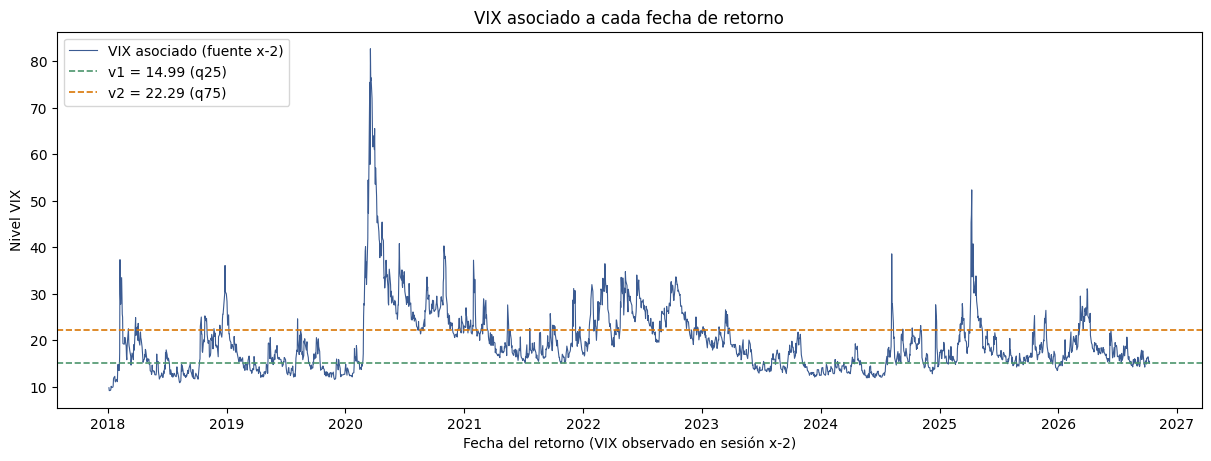

corte,valor_vix
str,f64
"""v1 = q0.25""",14.99
"""v2 = q0.75""",22.29


grupo,regla,observaciones,proporción,vix_mínimo,vix_máximo,media_vix,varianza_poblacional_vix,segundo_momento_vix
str,str,i64,f64,f64,f64,f64,f64,f64
"""VIX inferior""","""z_t ≤ 14.99""",551,0.250113,9.15,14.99,13.356715,1.113748,179.515585
"""VIX intermedio""","""14.99 < z_t ≤ 22.29""",1103,0.500681,15.0,22.29,18.078495,4.081168,330.91315
"""VIX superior""","""z_t > 22.29""",549,0.249206,22.33,82.69,29.002568,67.203297,908.352265


control,resultado
str,str
"""Cuantiles cumplen la definició…","""PASS"""
"""Cortes distintos y tres grupos…","""PASS"""
"""Pertenencia exhaustiva y mutua…","""PASS"""
"""Desigualdades y empates asigna…","""PASS"""
"""Vectores crisp finitos, no neg…","""PASS"""
"""Pesos interiores iguales a 1/n…","""PASS"""
"""Momentos concilian con cálculo…","""PASS"""
"""Objetos anteriores conservan i…","""PASS"""


Tolerancias: CDF/probabilidades = 1e-12; momentos absoluta = 1e-12 y relativa = 1e-11.
Los momentos mostrados describen el VIX asociado; los 125 retornos permanecen intactos y no se resumen por grupo.


In [6]:
import matplotlib.pyplot as plt

CDF_PROBABILITY_TOLERANCE = 1e-12
MOMENT_ABSOLUTE_TOLERANCE = 1e-12
MOMENT_RELATIVE_TOLERANCE = 1e-11

# Cuantiles de la CDF empírica uniforme, usando el índice ceil(T * alpha) - 1.
VIX_LOWER_ALPHA = 0.25
VIX_UPPER_ALPHA = 0.75
vix_lower_cut = empirical_quantile_inverse_cdf(z_historical, VIX_LOWER_ALPHA)
vix_upper_cut = empirical_quantile_inverse_cdf(z_historical, VIX_UPPER_ALPHA)

group_names = np.array(['VIX inferior', 'VIX intermedio', 'VIX superior'], dtype=object)
group_rules = np.array([f'z_t ≤ {vix_lower_cut:.2f}', f'{vix_lower_cut:.2f} < z_t ≤ {vix_upper_cut:.2f}', f'z_t > {vix_upper_cut:.2f}'], dtype=object)
vix_group_membership = np.select(
    [z_historical <= vix_lower_cut, (z_historical > vix_lower_cut) & (z_historical <= vix_upper_cut), z_historical > vix_upper_cut],
    [0, 1, 2],
    default=-1,
).astype(int)

p_crisp = np.zeros((T_aligned, 3), dtype=float)
group_rows: list[dict[str, float | int | str]] = []
group_masks: list[np.ndarray] = []
for group_index, (group_name, rule) in enumerate(zip(group_names, group_rules)):
    mask = vix_group_membership == group_index
    group_masks.append(mask)
    count = int(mask.sum())
    if count == 0:
        raise AssertionError(f'Grupo vacío: {group_name}.')
    p_crisp[mask, group_index] = 1.0 / count
    values = z_historical[mask]
    mean = float(np.dot(p_crisp[:, group_index], z_historical))
    variance = float(np.dot(p_crisp[:, group_index], np.square(z_historical - mean)))
    second_moment = float(np.dot(p_crisp[:, group_index], np.square(z_historical)))
    group_rows.append({
        'grupo': str(group_name), 'regla': str(rule), 'observaciones': count, 'proporción': count / T_aligned,
        'vix_mínimo': float(values.min()), 'vix_máximo': float(values.max()),
        'media_vix': mean, 'varianza_poblacional_vix': variance, 'segundo_momento_vix': second_moment,
    })

vix_group_summary = pl.DataFrame(group_rows)

def empirical_cdf_at(values: np.ndarray, threshold: float) -> float:
    return float(np.mean(values <= threshold))

def empirical_cdf_before(values: np.ndarray, threshold: float) -> float:
    return float(np.mean(values < threshold))

quantile_checks = []
for alpha, cut in ((VIX_LOWER_ALPHA, vix_lower_cut), (VIX_UPPER_ALPHA, vix_upper_cut)):
    quantile_checks.append(
        empirical_cdf_at(z_historical, cut) >= alpha - CDF_PROBABILITY_TOLERANCE
        and empirical_cdf_before(z_historical, cut) < alpha + CDF_PROBABILITY_TOLERANCE
        and cut in z_historical
    )

group_moment_checks = []
for group_index, mask in enumerate(group_masks):
    values = z_historical[mask]
    direct_mean = float(values.mean())
    direct_variance = float(np.mean(np.square(values - direct_mean)))
    direct_second_moment = float(np.mean(np.square(values)))
    row = group_rows[group_index]
    group_moment_checks.append(
        np.isclose(row['media_vix'], direct_mean, atol=MOMENT_ABSOLUTE_TOLERANCE, rtol=MOMENT_RELATIVE_TOLERANCE)
        and np.isclose(row['varianza_poblacional_vix'], direct_variance, atol=MOMENT_ABSOLUTE_TOLERANCE, rtol=MOMENT_RELATIVE_TOLERANCE)
        and np.isclose(row['segundo_momento_vix'], direct_second_moment, atol=MOMENT_ABSOLUTE_TOLERANCE, rtol=MOMENT_RELATIVE_TOLERANCE)
        and np.isclose(row['segundo_momento_vix'], row['media_vix'] ** 2 + row['varianza_poblacional_vix'], atol=MOMENT_ABSOLUTE_TOLERANCE, rtol=MOMENT_RELATIVE_TOLERANCE)
    )

crisp_group_controls = {
    'Cuantiles cumplen la definición de CDF empírica discreta': all(quantile_checks),
    'Cortes distintos y tres grupos no vacíos': vix_lower_cut < vix_upper_cut and all(mask.any() for mask in group_masks),
    'Pertenencia exhaustiva y mutuamente excluyente': (np.all(np.column_stack(group_masks).sum(axis=1) == 1) and np.array_equal(np.bincount(vix_group_membership, minlength=3), np.array([mask.sum() for mask in group_masks])) and np.all((vix_group_membership >= 0) & (vix_group_membership <= 2))),
    'Desigualdades y empates asignados exactamente': (np.all(vix_group_membership[z_historical <= vix_lower_cut] == 0) and np.all(vix_group_membership[(z_historical > vix_lower_cut) & (z_historical <= vix_upper_cut)] == 1) and np.all(vix_group_membership[z_historical > vix_upper_cut] == 2)),
    'Vectores crisp finitos, no negativos, normalizados y con soporte exacto': all(np.isfinite(p_crisp[:, j]).all() and (p_crisp[:, j] >= 0).all() and np.isclose(p_crisp[:, j].sum(), 1.0, atol=CDF_PROBABILITY_TOLERANCE, rtol=CDF_PROBABILITY_TOLERANCE) and np.array_equal(p_crisp[:, j] > 0, group_masks[j]) for j in range(3)),
    'Pesos interiores iguales a 1/n_j': all(np.allclose(p_crisp[group_masks[j], j], 1.0 / group_masks[j].sum(), atol=CDF_PROBABILITY_TOLERANCE, rtol=CDF_PROBABILITY_TOLERANCE) for j in range(3)),
    'Momentos concilian con cálculos directos y segundo momento': all(group_moment_checks),
    'Objetos anteriores conservan identidad y dimensiones': (A_log_returns_original.shape == (2204, 125) and A_log_returns_aligned.shape == (2203, 125) and z_historical.shape == (2203,) and p_uniform_reference.shape == (2203,) and p_exponential_reference.shape == (2203,) and np.array_equal(z_historical, vix_associated)),
}
if not all(crisp_group_controls.values()):
    raise AssertionError([name for name, passed in crisp_group_controls.items() if not passed])

fig, ax = plt.subplots(figsize=(12, 4.5), constrained_layout=True)
ax.plot(aligned_return_dates, z_historical, color='#3b5b92', linewidth=0.8, label='VIX asociado (fuente x-2)')
ax.axhline(vix_lower_cut, color='#4c956c', linestyle='--', linewidth=1.2, label=f'v1 = {vix_lower_cut:.2f} (q25)')
ax.axhline(vix_upper_cut, color='#d97706', linestyle='--', linewidth=1.2, label=f'v2 = {vix_upper_cut:.2f} (q75)')
ax.set(title='VIX asociado a cada fecha de retorno', xlabel='Fecha del retorno (VIX observado en sesión x-2)', ylabel='Nivel VIX')
ax.legend(loc='upper left', frameon=True)
plt.show()

display(pl.DataFrame({'corte': ['v1 = q0.25', 'v2 = q0.75'], 'valor_vix': [vix_lower_cut, vix_upper_cut]}))
display(vix_group_summary)
display(pl.DataFrame({'control': list(crisp_group_controls), 'resultado': ['PASS' if passed else 'FAIL' for passed in crisp_group_controls.values()]}))
print('Tolerancias: CDF/probabilidades = 1e-12; momentos absoluta = 1e-12 y relativa = 1e-11.')
print('Los momentos mostrados describen el VIX asociado; los 125 retornos permanecen intactos y no se resumen por grupo.')


### Cierre

Ya tenemos condiciones candidatas por grupo:

$$\sum_t q_{t,j}z_t=\mu_j,\qquad \sum_t q_{t,j}z_t^2\leq \mu_j^2+\sigma_j^2.$$

Todavía no las resolvemos. La siguiente pregunta será: **¿Cómo encontrar probabilidades que respeten estas condiciones y se aparten lo menos posible de la referencia exponencial?**

## 6. ¿Cómo combinar recencia y condiciones del estado?

Para cada grupo $j$ buscamos probabilidades ajustadas $q_{t,j}$ resolviendo:

$$\begin{aligned}
\min_q\; &\sum_t q_{t,j}\log\!\left(\frac{q_{t,j}}{p_t^{\mathrm{exp}}}\right)\\
\text{sujeto a}\; &\sum_t q_{t,j}=1,\quad q_{t,j}\geq0,\\
&\sum_t q_{t,j}z_t=\mu_j,\\
&\sum_t q_{t,j}z_t^2\leq\mu_j^2+\sigma_j^2.
\end{aligned}$$

La referencia es la distribución exponencial del bloque 3, con $\tau=1,102$. Los momentos se obtienen de las probabilidades crisp del bloque 5, utilizando valores completos en memoria y no los valores redondeados de sus tablas. Los tres ajustes usan las mismas 2,203 filas.

Para resolver de forma estable el dual convexo, definimos $a_t=(z_t-\mu_j)/\sigma_j$ y $b_t=a_t^2$. Entonces imponemos $E_q[a]=0$ y $E_q[b]\leq1$. Con $\lambda$ libre y $\eta\geq0$, la forma dual induce

$$q_t\propto p_t^{\mathrm{exp}}\exp(-\lambda a_t-\eta b_t),$$

y minimizamos $\log\sum_t p_t^{\mathrm{exp}}\exp(-\lambda a_t-\eta b_t)+\eta$. Esta formulación es equivalente a las restricciones originales cuando $\sigma_j>0$.

Las probabilidades ajustadas pueden asignar peso fuera del grupo que proporcionó los momentos. Cumplir estas condiciones no demuestra superioridad predictiva.

In [7]:
try:
    import scipy
    from scipy.optimize import minimize, root
    from scipy.special import logsumexp
except ModuleNotFoundError as exc:
    raise RuntimeError(
        'This block requires SciPy for bounded convex optimization. It is not available in the active kernel; '
        'do not replace it with an unvalidated method or use crisp probabilities as a substitute.'
    ) from exc

# Tolerances are fixed before solving; standardized residuals avoid dependence on VIX units.
OPTIMIZER_GRADIENT_TOLERANCE = 1e-10
OPTIMIZER_FUNCTION_TOLERANCE = 1e-12
STANDARDIZED_EQUALITY_TOLERANCE = 1e-9
STANDARDIZED_INEQUALITY_TOLERANCE = 1e-9
KKT_TOLERANCE = 1e-8
FINITE_DIFFERENCE_STEP = 1e-6
KL_TOLERANCE = 1e-12

if not np.isfinite(p_exponential_reference).all() or not np.all(p_exponential_reference > 0):
    raise AssertionError('The exponential reference must be strictly positive and finite.')
if not np.isclose(p_exponential_reference.sum(), 1.0, atol=PROBABILITY_ABSOLUTE_TOLERANCE, rtol=PROBABILITY_RELATIVE_TOLERANCE):
    raise AssertionError('The exponential reference is not normalized.')

log_p_exponential = np.log(p_exponential_reference)
mu_targets = np.array([float(row['media_vix']) for row in group_rows], dtype=float)
variance_targets = np.array([float(row['varianza_poblacional_vix']) for row in group_rows], dtype=float)
second_moment_limits = np.array([float(row['segundo_momento_vix']) for row in group_rows], dtype=float)
sigma_targets = np.sqrt(variance_targets)
if not np.isfinite(sigma_targets).all() or not np.all(sigma_targets > 0):
    raise AssertionError('Each crisp group must have a strictly positive, finite VIX standard deviation.')

def dual_value_gradient(theta: np.ndarray, a: np.ndarray, b: np.ndarray) -> tuple[float, np.ndarray, np.ndarray, np.ndarray]:
    lambda_multiplier, eta_multiplier = float(theta[0]), float(theta[1])
    log_unnormalized = log_p_exponential - lambda_multiplier * a - eta_multiplier * b
    log_normalizer = float(logsumexp(log_unnormalized))
    log_q = log_unnormalized - log_normalizer
    q = np.exp(log_q)
    expected_a = float(np.dot(q, a))
    expected_b = float(np.dot(q, b))
    value = log_normalizer + eta_multiplier
    gradient = np.array([-expected_a, 1.0 - expected_b], dtype=float)
    return value, gradient, q, log_q

def finite_difference_gradient(theta: np.ndarray, a: np.ndarray, b: np.ndarray, step: float) -> np.ndarray:
    approximation = np.empty(2, dtype=float)
    for coordinate in range(2):
        delta = np.zeros(2, dtype=float)
        delta[coordinate] = step
        upper = dual_value_gradient(theta + delta, a, b)[0]
        lower = dual_value_gradient(theta - delta, a, b)[0]
        approximation[coordinate] = (upper - lower) / (2.0 * step)
    return approximation

# The checks below use interior eta values, so central finite differences do not cross its bound.
gradient_check_points = (np.array([0.17, 0.23]), np.array([-0.41, 0.61]))
gradient_check_errors: list[float] = []
for group_index in range(3):
    standardized_a = (z_historical - mu_targets[group_index]) / sigma_targets[group_index]
    standardized_b = np.square(standardized_a)
    for point in gradient_check_points:
        analytic_gradient = dual_value_gradient(point, standardized_a, standardized_b)[1]
        numerical_gradient = finite_difference_gradient(point, standardized_a, standardized_b, FINITE_DIFFERENCE_STEP)
        gradient_check_errors.append(float(np.max(np.abs(analytic_gradient - numerical_gradient))))

Q_entropy_pooled = np.empty((T_aligned, 3), dtype=float)
log_Q_entropy_pooled = np.empty((T_aligned, 3), dtype=float)
entropy_pooling_rows: list[dict[str, float | int | str | bool]] = []
optimizer_results = []

for group_index, group_name in enumerate(group_names):
    a = (z_historical - mu_targets[group_index]) / sigma_targets[group_index]
    b = np.square(a)

    def objective(theta: np.ndarray) -> float:
        return dual_value_gradient(theta, a, b)[0]

    def gradient(theta: np.ndarray) -> np.ndarray:
        return dual_value_gradient(theta, a, b)[1]

    result = minimize(
        objective, x0=np.array([0.0, 0.1]), jac=gradient, method='SLSQP',
        bounds=[(None, None), (0.0, None)],
        options={'ftol': OPTIMIZER_FUNCTION_TOLERANCE, 'maxiter': 10_000, 'disp': False},
    )
    if not result.success:
        raise RuntimeError(f'Entropy-pooling optimizer did not converge for {group_name}: {result.message}')

    def dual_hessian(theta: np.ndarray) -> np.ndarray:
        _, _, hessian_q, _ = dual_value_gradient(theta, a, b)
        features = np.column_stack((a, b))
        centered = features - np.dot(hessian_q, features)
        return (centered * hessian_q[:, None]).T @ centered

    # SLSQP finds the bounded basin; an unconstrained Newton root polishes active eta > 0.
    polish = root(gradient, result.x, jac=dual_hessian, method='hybr', options={'xtol': 1e-12})
    if not polish.success or polish.x[1] < 0:
        raise RuntimeError(f'Dual optimality polish failed for {group_name}: {polish.message}')
    result.x = polish.x
    result.message = f'{result.message}; dual gradient polished with hybr.'

    dual_value, dual_gradient, q, log_q = dual_value_gradient(result.x, a, b)
    Q_entropy_pooled[:, group_index] = q
    log_Q_entropy_pooled[:, group_index] = log_q
    optimizer_results.append(result)

    obtained_mean = float(np.dot(q, z_historical))
    obtained_second_moment = float(np.dot(q, np.square(z_historical)))
    standardized_mean_residual = float(np.dot(q, a))
    standardized_second_moment = float(np.dot(q, b))
    inequality_slack = 1.0 - standardized_second_moment
    kl_divergence = float(np.sum(q * (log_q - log_p_exponential)))
    eta_multiplier = float(result.x[1])
    eta_kkt_residual = abs(float(dual_gradient[1])) if eta_multiplier > KKT_TOLERANCE else max(0.0, -float(dual_gradient[1]))
    inside_original_group_mass = float(q[group_masks[group_index]].sum())
    zero_weight_count = int(np.count_nonzero(q == 0.0))

    entropy_pooling_rows.append({
        'grupo': str(group_name), 'estado_optimizador': str(result.message), 'éxito': bool(result.success),
        'media_objetivo': float(mu_targets[group_index]), 'media_obtenida': obtained_mean,
        'segundo_momento_máximo': float(second_moment_limits[group_index]), 'segundo_momento_obtenido': obtained_second_moment,
        'holgura_estandarizada': inequality_slack, 'suma_probabilidades': float(q.sum()),
        'N_eff': effective_sample_size(q), 'KL_q_p_exp': kl_divergence,
        'masa_grupo_original': inside_original_group_mass, 'masa_fuera_grupo': float(1.0 - inside_original_group_mass),
        'lambda': float(result.x[0]), 'eta': eta_multiplier,
        'residuo_igualdad_estandarizado': standardized_mean_residual,
        'residuo_desigualdad_estandarizado': max(0.0, -inequality_slack),
        'residuo_estacionariedad_lambda': abs(float(dual_gradient[0])),
        'residuo_kkt_eta': eta_kkt_residual, 'residuo_complementariedad': abs(eta_multiplier * float(dual_gradient[1])),
        'probabilidades_cero_por_underflow': zero_weight_count,
    })

entropy_pooling_summary = pl.DataFrame(entropy_pooling_rows)

entropy_pooling_controls = {
    'Gradiente analítico concilia con diferencias finitas': max(gradient_check_errors) <= 1e-7,
    'Los tres optimizadores reportan convergencia': all(result.success for result in optimizer_results),
    'Q tiene dimensión 2,203 × 3 y conserva el orden de filas': Q_entropy_pooled.shape == (2203, 3) and np.array_equal(aligned_dates_for_state, aligned_return_dates),
    'Q es finita, no negativa y normalizada por grupo': all(np.isfinite(Q_entropy_pooled[:, j]).all() and (Q_entropy_pooled[:, j] >= 0).all() and np.isclose(Q_entropy_pooled[:, j].sum(), 1.0, atol=PROBABILITY_ABSOLUTE_TOLERANCE, rtol=PROBABILITY_RELATIVE_TOLERANCE) for j in range(3)),
    'Media y segundo momento originales respetan objetivos': all(np.isclose(row['media_obtenida'], row['media_objetivo'], atol=STANDARDIZED_EQUALITY_TOLERANCE * sigma_targets[j], rtol=0.0) and row['segundo_momento_obtenido'] <= row['segundo_momento_máximo'] + STANDARDIZED_INEQUALITY_TOLERANCE * sigma_targets[j] ** 2 for j, row in enumerate(entropy_pooling_rows)),
    'Restricciones estandarizadas y KKT respetados': all(abs(row['residuo_igualdad_estandarizado']) <= STANDARDIZED_EQUALITY_TOLERANCE and row['residuo_desigualdad_estandarizado'] <= STANDARDIZED_INEQUALITY_TOLERANCE and row['residuo_estacionariedad_lambda'] <= KKT_TOLERANCE and row['residuo_kkt_eta'] <= KKT_TOLERANCE and row['residuo_complementariedad'] <= KKT_TOLERANCE and row['eta'] >= -KKT_TOLERANCE for row in entropy_pooling_rows),
    'KL es finita y no negativa dentro de tolerancia': all(np.isfinite(row['KL_q_p_exp']) and row['KL_q_p_exp'] >= -KL_TOLERANCE for row in entropy_pooling_rows),
    'Entradas y objetos previos se preservan': (A_log_returns_original.shape == (2204, 125) and A_log_returns_aligned.shape == (2203, 125) and z_historical.shape == (2203,) and p_exponential_reference.shape == (2203,) and p_crisp.shape == (2203, 3) and np.array_equal(z_historical, vix_associated)),
}
if not all(entropy_pooling_controls.values()):
    raise AssertionError([name for name, passed in entropy_pooling_controls.items() if not passed])

display(entropy_pooling_summary.select([
    'grupo', 'media_objetivo', 'media_obtenida', 'segundo_momento_máximo', 'segundo_momento_obtenido',
    'holgura_estandarizada', 'suma_probabilidades', 'N_eff', 'KL_q_p_exp',
    'masa_grupo_original', 'masa_fuera_grupo', 'éxito',
    'residuo_igualdad_estandarizado', 'residuo_desigualdad_estandarizado',
    'residuo_estacionariedad_lambda', 'residuo_kkt_eta', 'residuo_complementariedad',
    'probabilidades_cero_por_underflow',
]))
display(pl.DataFrame({'control': list(entropy_pooling_controls), 'resultado': ['PASS' if passed else 'FAIL' for passed in entropy_pooling_controls.values()]}))
print(f'SciPy {scipy.__version__}; error máximo de gradiente analítico vs. diferencias finitas: {max(gradient_check_errors):.3e}.')
print('Los log-pesos se conservan en log_Q_entropy_pooled para diagnóstico; no se aplicaron pisos artificiales.')


grupo,media_objetivo,media_obtenida,segundo_momento_máximo,segundo_momento_obtenido,holgura_estandarizada,suma_probabilidades,N_eff,KL_q_p_exp,masa_grupo_original,masa_fuera_grupo,éxito,residuo_igualdad_estandarizado,residuo_desigualdad_estandarizado,residuo_estacionariedad_lambda,residuo_kkt_eta,residuo_complementariedad,probabilidades_cero_por_underflow
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,bool,f64,f64,f64,f64,f64,i64
"""VIX inferior""",13.356715,13.356715,179.515585,179.515585,0.0,1.0,496.054965,1.313009,0.919621,0.080379,true,4.4669e-17,0.0,4.4669e-17,0.0,0.0,5
"""VIX intermedio""",18.078495,18.078495,330.91315,330.91315,1.1102e-16,1.0,998.023355,0.455573,0.92393,0.07607,true,4.9223e-17,0.0,4.9223e-17,1.1102e-16,4.5160e-17,0
"""VIX superior""",29.002568,29.002568,908.352265,908.352265,0.0,1.0,514.773312,0.997557,0.788446,0.211554,true,-1.7564e-16,0.0,1.7564e-16,0.0,0.0,0


control,resultado
str,str
"""Gradiente analítico concilia c…","""PASS"""
"""Los tres optimizadores reporta…","""PASS"""
"""Q tiene dimensión 2,203 × 3 y …","""PASS"""
"""Q es finita, no negativa y nor…","""PASS"""
"""Media y segundo momento origin…","""PASS"""
"""Restricciones estandarizadas y…","""PASS"""
"""KL es finita y no negativa den…","""PASS"""
"""Entradas y objetos previos se …","""PASS"""


SciPy 1.15.2; error máximo de gradiente analítico vs. diferencias finitas: 3.646e-10.
Los log-pesos se conservan en log_Q_entropy_pooled para diagnóstico; no se aplicaron pisos artificiales.


### Cierre

Construimos tres distribuciones ajustadas sobre las mismas 2,203 observaciones: cada una combina la referencia de recencia exponencial con los momentos de VIX de un grupo crisp. Aún falta comprobar su uso fuera de muestra y cualquier capacidad predictiva antes de simular; en particular, todavía no se han calculado ni interpretado retornos bajo estas probabilidades.